# Experiment 3: Three new tests on Dr Li's FPFLI (no retraining)
**Forhad Islam.** Runs on my RTX 3090. Uses his released models and sample data.

* **A. Which layers can be squeezed to 4 bit?** Each LLE layer at 4 bit on its own, then mixed precision.
  Finding: the final dense layer holds 57% of the weights **and** is the most sensitive.
* **B. How few photons is too few?** Photon thinning down to about 1 photon per pixel, compared with the classic centre of mass method (CMM).
  Finding: FPFLI is far better at normal light, but below about 2 photons per pixel CMM does as well.
* **C. Can FPFLI show where it is unsure?** An uncertainty map from photon resampling, checked against the real error.
  Finding: partly on synthetic data, weakly on real cells, where most error is smoothing bias.

In [1]:
import os, sys, glob, subprocess, warnings
warnings.filterwarnings("ignore")
HERE = os.getcwd()                                                       # this experiment's folder
BASE = HERE                                                          # find the University of Strathclyde folder (works at any depth)
while not os.path.isdir(os.path.join(BASE, "04_Shared_Code_and_Data")) and os.path.dirname(BASE) != BASE:
    BASE = os.path.dirname(BASE)
CODE = os.path.join(BASE, "04_Shared_Code_and_Data", "Dr_Li_FPFLI_code")  # Dr Li's FPFLI code, models and sample data
DATA = os.path.join(BASE, "04_Shared_Code_and_Data", "Datasets")
GLASGOW = os.path.join(DATA, "SPAD_FLIM_Glasgow_Zickus2020",
    "DATA_REPOSITORY_fluorescence_lifetime_imaging_with_a_megapixel_SPAD_camera_and_neural_network_lifetime_estimation")
try:
    import mat73
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "mat73"], check=True); import mat73
sys.path.insert(0, CODE); os.chdir(CODE)     # Dr Li's code uses paths like sample_data/... and ./model_parameters/...
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")
print("results will be saved in:", HERE)

GPU: NVIDIA GeForce RTX 3090
results will be saved in: <project>\03_Experiments\E3_FPFLI_Experiments_A_B_C


## The code

**What this code does** (from the script `new_experiments.py`):

```
new_experiments.py  (Forhad's own extensions of FPFLI, Xiao, Sapermsap, Chen and Li, Optica 2023)

Uses only the group's released code, pretrained models and sample data. No retraining.

Experiment A: Which layers of the lifetime network can be squeezed to 4 bit?
              Layer by layer sensitivity, then a mixed precision version for an FPGA.
Experiment B: How few photons is too few? Photon thinning down to about 1 photon per pixel,
              and a comparison with the classic centre of mass method (CMM), which needs no network.
Experiment C: Can FPFLI tell us where it is unsure? A per pixel uncertainty map from photon
              resampling, checked against the real error.

Run inside the Evaluation folder:  python new_experiments.py   (add --quick for fewer repeats)
```

### Setup: imports and settings

In [2]:
import os, sys, json, time, warnings
import numpy as np
import torch
warnings.filterwarnings("ignore")
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})

import scipy.io as io
import mat73
from scipy.stats import spearmanr
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from Neural_implict_interploation import NIII_process
import builtins

QUICK = "--quick" in sys.argv
OUT = os.path.join(HERE, "my_new_results"); os.makedirs(OUT, exist_ok=True)
P, BIN = 8, 0.039
LLE_A = "./model_parameters/LLE_parameter.pth"
LLE_B = "./model_parameters/LLE_parameter_1_3ns.pth"
rng = np.random.default_rng(0)

# silence the timer prints from the original code
_print = builtins.print
def quiet(f, *a, **k):
    builtins.print = lambda *x, **y: None
    try: return f(*a, **k)
    finally: builtins.print = _print

### Helpers

In [3]:
def groups(model):
    return [n[:-7] for n, p in model.named_parameters() if p.dim() >= 2 and n.endswith(".weight")]

def nparams(model):
    return {n[:-7]: p.numel() for n, p in model.named_parameters() if p.dim() >= 2 and n.endswith(".weight")}

def quantise(model, bitmap):
    """bitmap: {group_name: bits}; per output channel symmetric weight quantisation."""
    with torch.no_grad():
        for n, p in model.named_parameters():
            g = n[:-7]
            if g not in bitmap or bitmap[g] is None: continue
            qmax = 2 ** (bitmap[g] - 1) - 1
            flat = p.data.reshape(p.shape[0], -1)
            s = flat.abs().max(1, keepdim=True).values.clamp(min=1e-12) / qmax
            p.data.copy_((torch.round(flat / s).clamp(-qmax, qmax) * s).reshape(p.shape))

def lle(hist_m, irf, path, thres=50, bitmap=None):
    obj = PLL.Pred_local_lifetime(hist_m, irf, scaling_ratio=P, h=BIN, thres=thres, file_path=path)
    if bitmap: quantise(PLL.model, bitmap)
    return obj.eval_local_tau()

def cmm(hist_m, irf, thres=50):
    """Centre of mass lifetime per 8x8 patch: mean photon arrival time minus mean IRF time."""
    H, W, L = hist_m.shape
    patch = hist_m.reshape(H // P, P, W // P, P, L).sum((1, 3))
    t = np.arange(L) * BIN
    n = patch.sum(-1)
    tau = (patch * t).sum(-1) / np.maximum(n, 1e-8) - (irf.ravel() * t).sum() / irf.sum()
    tau[n <= thres] = 0
    return np.clip(tau, 0, None).astype("float32")

def niii(mask, lr_tau):
    out = np.squeeze(quiet(NIII_process, prep_exp_data(mask, lr_tau).prep_data(), ratio=P), (0, 1))
    out[out < 0] = 0
    return out

In [4]:
def masked(hist, thres):
    inten = hist.sum(2); keep = inten > thres
    return hist * keep[..., None], inten * keep

def mae(pred, gt, mask):
    m = (mask > 0) & (gt > 0)
    return float(np.mean(np.abs(pred[m] - gt[m])))

def patch_gt(gt, mask):
    """Ground truth averaged over each 8x8 patch, for judging the LLE stage alone."""
    H, W = gt.shape
    g = (gt * (mask > 0)).reshape(H // P, P, W // P, P).sum((1, 3))
    c = (mask > 0).reshape(H // P, P, W // P, P).sum((1, 3))
    return np.where(c > 0, g / np.maximum(c, 1), 0)

### Data

In [5]:
irf_g = io.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32")
synth = {}
for s in ["1", "2", "3", "4", "5", "6"]:
    d = io.loadmat(f"sample_data/{s}.mat")
    synth[s] = (d["Hist"].astype("float32"), d["tau_gt"].astype("float32"))
d = io.loadmat("sample_data/hek_low.mat")
hek = (d["hist"].astype("float32"), d["irf"].astype("float32"),
       mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32"))
R = {}

### A: mixed precision

In [6]:
print("\n=== Experiment A: layer sensitivity and mixed precision ===")
model = PLL.model
G = groups(model); NP = nparams(model); total = sum(NP.values())
cases = [(masked(synth[s][0], 3), irf_g, LLE_A) for s in synth] + [(masked(hek[0], 3), hek[1], LLE_B)]
ref = [lle(hm, irf, path) for (hm, _), irf, path in cases]

def lle_change(bitmap):
    errs = []
    for ((hm, _), irf, path), r in zip(cases, ref):
        t = lle(hm, irf, path, bitmap=bitmap); m = r > 0
        errs.append(np.abs(t[m] - r[m]))
    return float(np.median(np.concatenate(errs)))

sens = {g: lle_change({g: 4}) for g in G}
for g in sorted(sens, key=sens.get, reverse=True):
    print(f"  {g:34s} {NP[g]:6d} weights   4 bit alone -> median change {sens[g]:.3f} ns")
all8 = lle_change({g: 8 for g in G}); all4 = lle_change({g: 4 for g in G})

# greedy: move the most sensitive layers to 8 bit until the change is close to the all INT8 change
order = sorted(G, key=lambda g: sens[g], reverse=True)
path_rows, eight = [], []
target = max(2 * all8, 0.01)
for k in range(len(order) + 1):
    bm = {g: (8 if g in eight else 4) for g in G}
    ch = lle_change(bm)
    kb = sum(NP[g] * bm[g] for g in G) / 8 / 1024
    path_rows.append({"layers_at_8bit": k, "median_change_ns": ch, "weight_KB": kb})
    print(f"  {k:2d} layers at 8 bit, rest 4 bit: change {ch:.3f} ns, weights {kb:.1f} KB")
    if ch <= target: break
    eight.append(order[k])
best = {g: (8 if g in eight else 4) for g in G}
fp32_kb, int8_kb = total * 4 / 1024, total / 1024
mixed_kb = sum(NP[g] * best[g] for g in G) / 8 / 1024

# full pipeline accuracy with the mixed model
full = {}
for name, bm in [("FP32", None), ("INT8", {g: 8 for g in G}), ("INT4", {g: 4 for g in G}), ("Mixed", best)]:
    e = []
    for s in synth:
        hm, mk = masked(synth[s][0], 3); e.append(mae(niii(mk, lle(hm, irf_g, LLE_A, bitmap=bm)), synth[s][1], mk))
    hm, mk = masked(hek[0], 3)
    full[name] = {"synthetic_mean_MAE_ns": float(np.mean(e)),
                  "hek_MAE_ns": mae(niii(mk, lle(hm, hek[1], LLE_B, bitmap=bm)), hek[2], mk)}
    print(f"  full pipeline {name:6s}: synthetic MAE {full[name]['synthetic_mean_MAE_ns']:.3f} ns, HEK MAE {full[name]['hek_MAE_ns']:.3f} ns")
R["A_mixed_precision"] = dict(sensitivity_ns=sens, weights_per_layer=NP, all_int8_change=all8, all_int4_change=all4,
                              greedy=path_rows, layers_kept_8bit=eight, KB={"FP32": fp32_kb, "INT8": int8_kb, "Mixed": mixed_kb,
                              "INT4": total / 2 / 1024}, full_pipeline=full)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
o = sorted(G, key=lambda g: sens[g], reverse=True)
short = [g.replace("conv_blocks.", "b").replace(".res.0.fn.0", ".dw").replace(".ponitconv", ".pw").replace("ponitconv", "head") for g in o]
ax[0].bar(range(len(o)), [sens[g] for g in o], color=["#c0392b" if g in eight else "#7f8c8d" for g in o])
ax[0].set_xticks(range(len(o))); ax[0].set_xticklabels(short, rotation=90, fontsize=8)
ax[0].set_ylabel("median lifetime change (ns)"); ax[0].set_title("Each layer put at 4 bit on its own (red = kept at 8 bit)")
names = ["FP32", "INT8", "Mixed", "INT4"]
kb = [fp32_kb, int8_kb, mixed_kb, total / 2 / 1024]
er = [full[n]["hek_MAE_ns"] for n in names]
ax[1].scatter(kb, er, s=80)
for n, x, y in zip(names, kb, er): ax[1].annotate(n, (x, y), textcoords="offset points", xytext=(6, 6))
ax[1].set_xlabel("LLE weight memory (KB)"); ax[1].set_ylabel("error on real HEK293 cells (ns)")
ax[1].set_title("Memory against accuracy")
fig.tight_layout(); fig.savefig(f"{OUT}/figA_mixed_precision.png", dpi=130); plt.close(fig)


=== Experiment A: layer sensitivity and mixed precision ===
  ponitconv1                          16384 weights   4 bit alone -> median change 0.607 ns
  ponitconv3                              8 weights   4 bit alone -> median change 0.390 ns
  conv_blocks.0.res.0.fn.0              288 weights   4 bit alone -> median change 0.202 ns
  conv_blocks.0.ponitconv              1024 weights   4 bit alone -> median change 0.177 ns
  conv_blocks.7.ponitconv              1024 weights   4 bit alone -> median change 0.171 ns
  conv_blocks.1.ponitconv              1024 weights   4 bit alone -> median change 0.156 ns
  conv_blocks.2.ponitconv              1024 weights   4 bit alone -> median change 0.116 ns
  ponitconv2                            128 weights   4 bit alone -> median change 0.079 ns
  conv_blocks.7.res.0.fn.0              288 weights   4 bit alone -> median change 0.074 ns
  conv_blocks.4.ponitconv              1024 weights   4 bit alone -> median change 0.073 ns
  conv_blocks.2.res

### B: photon limit

In [7]:
print("\n=== Experiment B: how few photons is too few? ===")
fracs = [1.0, 0.5, 0.3, 0.2, 0.1] if not QUICK else [1.0, 0.3, 0.1]
B = {"FPFLI": {}, "CMM+NIII": {}, "photons_per_pixel": {}}
tests = [("synthetic " + s, synth[s][0], irf_g, synth[s][1], LLE_A) for s in (["1", "3", "5"] if not QUICK else ["3"])]
tests += [("HEK293 real", hek[0], hek[1], hek[2], LLE_B)]
for f in fracs:
    ef, ec, ph = [], [], []
    for name, hist, irf, gt, path in tests:
        _, mk = masked(hist, 3)                      # same cell outline at every photon level
        thin = rng.binomial(hist.astype(np.int64), f).astype("float32") * (mk > 0)[..., None]
        ph.append(thin.sum(2)[mk > 0].mean())
        ef.append(mae(niii(mk, lle(thin, irf, path, thres=50 * f)), gt, mk))
        ec.append(mae(niii(mk, cmm(thin, irf, thres=50 * f)), gt, mk))
    B["FPFLI"][f] = ef; B["CMM+NIII"][f] = ec; B["photons_per_pixel"][f] = ph
    print(f"  {f:.0%} of photons (~{np.mean(ph):.1f} per pixel): FPFLI {np.round(ef,3)}  CMM+NIII {np.round(ec,3)}")
R["B_photon_limit"] = {"tests": [t[0] for t in tests], **{k: {str(a): b for a, b in v.items()} for k, v in B.items()}}
fig, ax = plt.subplots(figsize=(6, 4))
for i, (name, *_ ) in enumerate(tests):
    x = [B["photons_per_pixel"][f][i] for f in fracs]
    ax.plot(x, [B["FPFLI"][f][i] for f in fracs], "o-", color=f"C{i}", label=f"FPFLI, {name}")
    ax.plot(x, [B["CMM+NIII"][f][i] for f in fracs], "s--", color=f"C{i}", alpha=.6, label=f"CMM+NIII, {name}")
ax.set_xscale("log"); ax.set_xlabel("photons per pixel"); ax.set_ylabel("mean absolute error (ns)")
ax.set_title("Accuracy as photons run out"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f"{OUT}/figB_photon_limit.png", dpi=130); plt.close(fig)


=== Experiment B: how few photons is too few? ===
  100% of photons (~11.2 per pixel): FPFLI [0.085 0.088 0.346 0.134]  CMM+NIII [0.574 0.244 0.557 0.388]
  50% of photons (~5.6 per pixel): FPFLI [0.243 0.119 0.408 0.171]  CMM+NIII [0.59  0.254 0.57  0.388]
  30% of photons (~3.4 per pixel): FPFLI [0.354 0.204 0.468 0.243]  CMM+NIII [0.544 0.255 0.601 0.376]
  20% of photons (~2.2 per pixel): FPFLI [0.487 0.333 0.59  0.281]  CMM+NIII [0.593 0.26  0.563 0.408]
  10% of photons (~1.1 per pixel): FPFLI [0.585 0.571 0.75  0.399]  CMM+NIII [0.596 0.276 0.677 0.46 ]


### C: uncertainty map

In [8]:
print("\n=== Experiment C: where is FPFLI unsure? ===")
K = 10 if not QUICK else 5
C = {}
for name, hist, irf, gt, path in [("synthetic 3", synth["3"][0], irf_g, synth["3"][1], LLE_A),
                                   ("HEK293 real", hek[0], hek[1], hek[2], LLE_B)]:
    hm, mk = masked(hist, 3)
    base = niii(mk, lle(hm, irf, path))
    reps = np.stack([niii(mk, lle(rng.poisson(hm).astype("float32"), irf, path)) for _ in range(K)])
    unc = reps.std(0); err = np.abs(base - gt)
    m = (mk > 0) & (gt > 0)
    rho = spearmanr(unc[m], err[m]).correlation
    top = unc[m] >= np.quantile(unc[m], 0.9)
    C[name] = {"spearman_uncertainty_vs_error": float(rho),
               "MAE_most_uncertain_10pct_ns": float(err[m][top].mean()),
               "MAE_other_90pct_ns": float(err[m][~top].mean()),
               "MAE_if_flagged_pixels_removed_ns": float(err[m][~top].mean()), "MAE_all_ns": float(err[m].mean())}
    print(f"  {name}: Spearman(uncertainty, error) = {rho:.2f}; error in most uncertain 10% = {C[name]['MAE_most_uncertain_10pct_ns']:.3f} ns vs {C[name]['MAE_other_90pct_ns']:.3f} ns elsewhere")
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for a, im, t, cm, vmax in [(ax[0], base, "FPFLI lifetime", "inferno", 4 if "syn" in name else 2.5),
                               (ax[1], unc * m, "uncertainty (std over resamples)", "viridis", np.quantile(unc[m], .99)),
                               (ax[2], err * m, "true error", "viridis", np.quantile(err[m], .99))]:
        h = a.imshow(im, cmap=cm, vmin=0, vmax=vmax); a.set_title(t); a.axis("off"); fig.colorbar(h, ax=a, shrink=.7, label="ns")
    fig.suptitle(f"{name}: Spearman correlation between uncertainty and error = {rho:.2f}")
    fig.tight_layout(); fig.savefig(f"{OUT}/figC_uncertainty_{name.split()[0]}.png", dpi=130); plt.close(fig)
R["C_uncertainty"] = C

json.dump(R, open(f"{OUT}/new_results.json", "w"), indent=2, default=float)
print("\nSaved to", OUT)


=== Experiment C: where is FPFLI unsure? ===
  synthetic 3: Spearman(uncertainty, error) = 0.34; error in most uncertain 10% = 0.273 ns vs 0.068 ns elsewhere
  HEK293 real: Spearman(uncertainty, error) = 0.09; error in most uncertain 10% = 0.182 ns vs 0.129 ns elsewhere

Saved to <project>\03_Experiments\E3_FPFLI_Experiments_A_B_C\my_new_results


### Figures

figA_mixed_precision.png


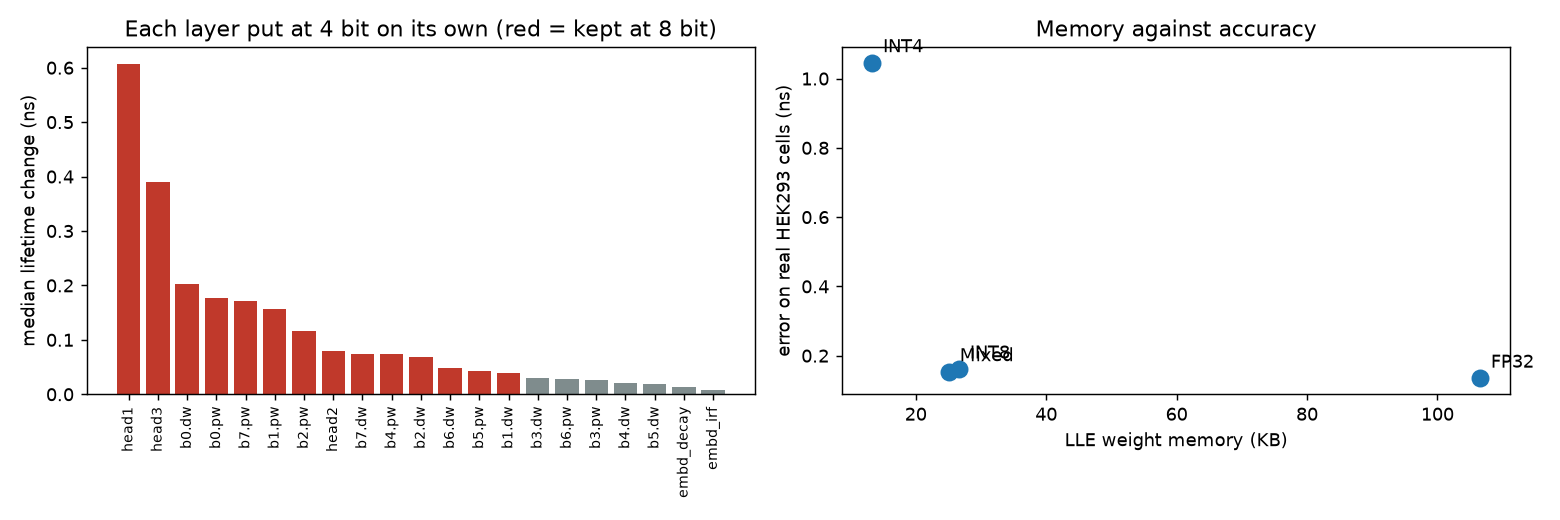

figB_photon_limit.png


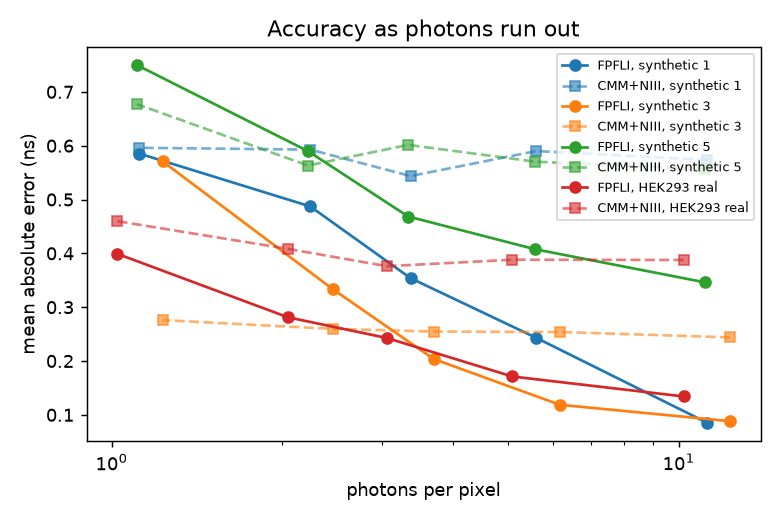

figC_uncertainty_HEK293.png


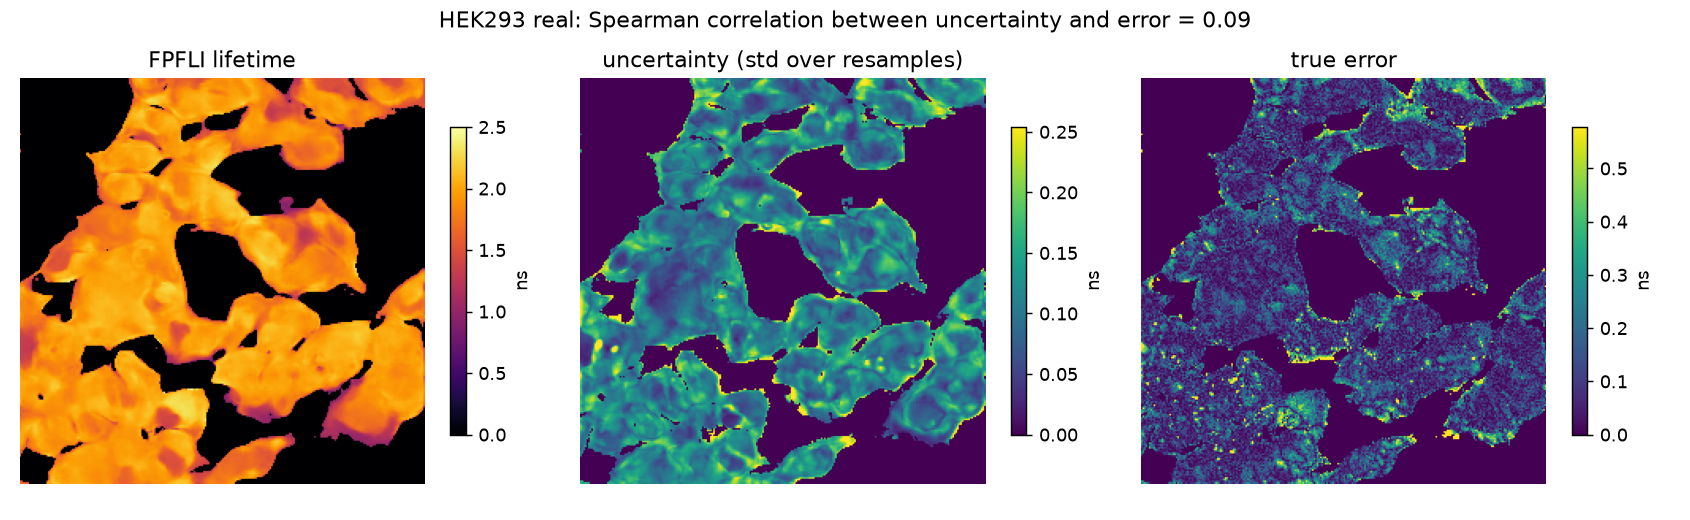

figC_uncertainty_synthetic.png


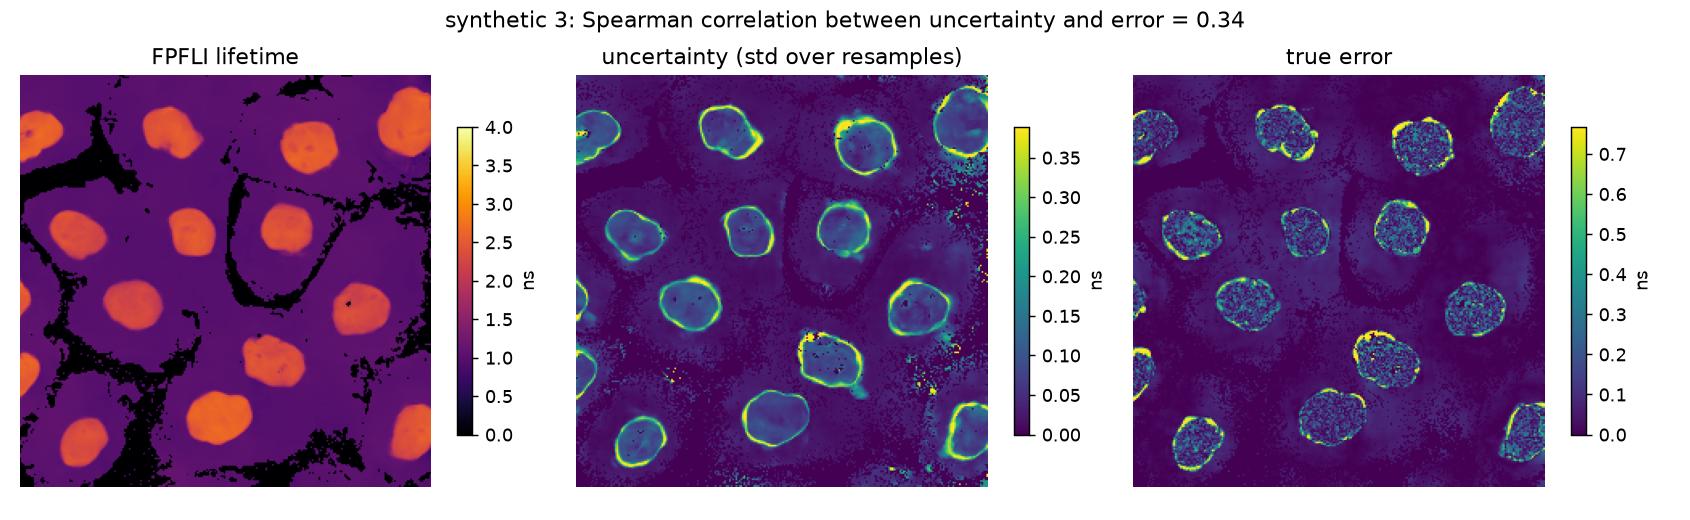

In [9]:
from IPython.display import Image, display
for f in sorted(glob.glob(os.path.join(OUT, "*.png"))):
    print(os.path.basename(f)); display(Image(filename=f, width=950))